Ahmed Amer Alshehri 2230002008 9MA2

# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

### Task solution

#### 1. Load `bert-base-uncased` and print the number of layers and attention heads

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

# attn_implementation="eager" makes the model return its attention weights
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)
print("Hidden size:", bert_model.config.hidden_size)

Transformer layers: 12
Attention heads per layer: 12
Hidden size: 768


#### 2. Total number of attention heads across all layers

In [7]:
total_heads = num_layers * num_heads

print(f"Total attention heads: {num_layers} layers x {num_heads} heads = {total_heads}")

Total attention heads: 12 layers x 12 heads = 144


#### 3. Attention weights from the third layer and second attention head

Python indexing starts at 0, so the **third layer** is index `2` and the **second head** is index `1`.

In [8]:
bert_sentence = "Transformers use self-attention to understand language."

bert_inputs = bert_tokenizer(bert_sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs, output_attentions=True)

# attentions is a tuple with one tensor per layer: (batch, heads, tokens, tokens)
print("Number of attention tensors (one per layer):", len(bert_outputs.attentions))
print("Shape of each tensor:", tuple(bert_outputs.attentions[0].shape))

layer_index = 2   # third Transformer layer
head_index = 1    # second attention head
bert_attention = bert_outputs.attentions[layer_index][0, head_index]

torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)
print("\nTokens:", bert_tokens)
print("Number of tokens:", len(bert_tokens))
print("Attention shape:", tuple(bert_attention.shape))
print("Attention weights (layer 3, head 2):\n", bert_attention)
print("\nSum of each row:", bert_attention.sum(dim=1))

Number of attention tensors (one per layer): 12
Shape of each tensor: (1, 12, 11, 11)

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Number of tokens: 11
Attention shape: (11, 11)
Attention weights (layer 3, head 2):
 tensor([[0.7318, 0.0079, 0.0106, 0.0056, 0.0165, 0.0069, 0.0101, 0.0116, 0.0055, 0.0386, 0.1550],
        [0.8888, 0.0047, 0.0344, 0.0002, 0.0027, 0.0051, 0.0009, 0.0007, 0.0004, 0.0051, 0.0570],
        [0.1427, 0.5689, 0.0054, 0.0353, 0.0412, 0.0679, 0.0896, 0.0003, 0.0053, 0.0090, 0.0343],
        [0.3395, 0.0732, 0.0015, 0.0002, 0.2016, 0.0811, 0.0636, 0.0257, 0.0016, 0.0285, 0.1835],
        [0.1429, 0.0697, 0.0713, 0.6394, 0.0121, 0.0128, 0.0034, 0.0026, 0.0142, 0.0093, 0.0223],
        [0.1126, 0.5448, 0.0116, 0.0203, 0.1112, 0.0102, 0.0724, 0.0001, 0.0001, 0.0164, 0.1003],
        [0.0841, 0.0224, 0.6222, 0.0085, 0.0091, 0.1936, 0.0110, 0.0072, 0.0008, 0.0140, 0.0271],
        [0.4336, 0.0050, 0.00

In [9]:
# For every token (row), show the token it attends to the most (column)
for i, token in enumerate(bert_tokens):
    j = bert_attention[i].argmax().item()
    print(f"{token:>12} -> {bert_tokens[j]:<12} (weight {bert_attention[i, j].item():.3f})")

       [CLS] -> [CLS]        (weight 0.732)
transformers -> [CLS]        (weight 0.889)
         use -> transformers (weight 0.569)
        self -> [CLS]        (weight 0.340)
           - -> self         (weight 0.639)
   attention -> transformers (weight 0.545)
          to -> use          (weight 0.622)
  understand -> [CLS]        (weight 0.434)
    language -> use          (weight 0.429)
           . -> [CLS]        (weight 0.658)
       [SEP] -> [CLS]        (weight 0.828)


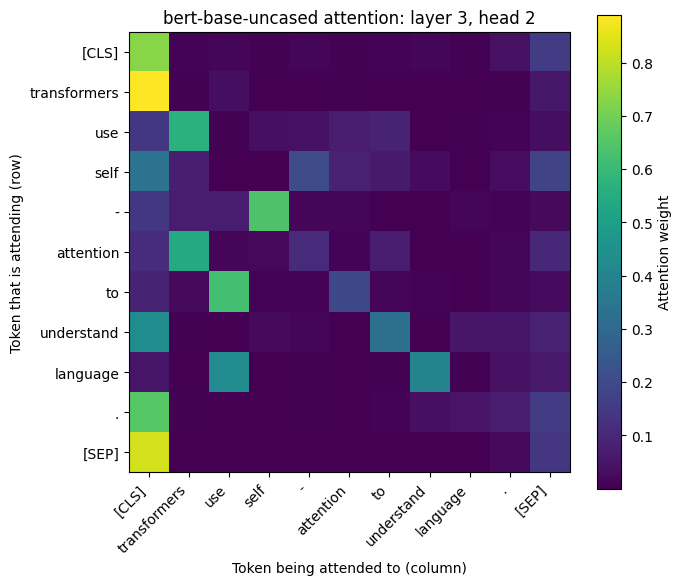

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(bert_attention.numpy(), cmap="viridis")
ax.set_xticks(range(len(bert_tokens)))
ax.set_yticks(range(len(bert_tokens)))
ax.set_xticklabels(bert_tokens, rotation=45, ha="right")
ax.set_yticklabels(bert_tokens)
ax.set_xlabel("Token being attended to (column)")
ax.set_ylabel("Token that is attending (row)")
ax.set_title("bert-base-uncased attention: layer 3, head 2")
fig.colorbar(im, ax=ax, label="Attention weight")
plt.tight_layout()
plt.show()

#### 4. What do the rows and columns of the attention matrix represent?

The sentence is split into **11 tokens** (`[CLS]`, `transformers`, `use`, `self`, `-`, `attention`, `to`, `understand`, `language`, `.`, `[SEP]`), so the attention matrix of one head is **11 × 11** — one row and one column for every token.

- **Rows** = the token that is *attending* (the **query** token, i.e. the token whose representation is being updated).
- **Columns** = the token that is *being attended to* (the **key** token, i.e. where the information comes from).
- The value at `[i, j]` is how much attention token `i` gives to token `j` when it builds its new contextual representation.
- The weights come from a softmax, so **each row sums to 1**: a row is a probability distribution over all tokens in the sentence (the columns do not have to sum to 1).

**Example from the output above (layer 3, head 2):** in the row for `use`, the largest weight (0.569) is in the column for `transformers`, so when the model updates `use` it mostly looks at `transformers`. In the same way `-` attends mostly to `self` (0.639) and `to` attends mostly to `use` (0.622). Many rows also give a large weight to the special `[CLS]` token.

Each of the 144 heads (12 layers × 12 heads) has its own matrix like this one, so different heads can focus on different relationships between the words.